In [34]:
# %% [markdown]
# # Análise Estatística: Cenário A (sem TAS) vs. Cenário B (com TAS)
#
# Este notebook carrega os resultados das duas simulações OMNeT++/INET
# (`ScenarioA_NoTAS` e `ScenarioB_WithTAS`), separa os dados em dois
# DataFrames, calcula estatísticas descritivas (média, desvio padrão,
# mediana, percentis, jitter) e gera gráficos comparativos.
#
# **Métrica utilizada:** `meanBitLifeTimePerPacket`, que é a estatística
# padrão do `UdpSinkApp` do INET 4.6 para medir latência fim-a-fim
# (tempo de vida do pacote da criação à destruição).
#
# **Pré-requisito:** os arquivos `.sca` e `.vec` gerados pelas simulações

# ## 1. Configuração e imports

# %%
import glob
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.figsize"] = (12, 6)

# Caminho para o diretório de resultados do showcase
RESULTS_DIR = os.path.expanduser(
    "~/inet-workspace/inet-4.6.0/showcases/tsn/trafficshaping/timeawareshaper/results"
)

# Nome da estatística de latência no UdpSinkApp do INET 4.6
LATENCY_STAT = "meanBitLifeTimePerPacket"



In [35]:
# %% [markdown]
# ## 2. Funções auxiliares para ler arquivos `.sca` e `.vec` do OMNeT++

# %%
def parse_sca(path):
    """Lê um arquivo .sca e retorna um DataFrame com run, módulo, nome, valor."""
    rows = []
    run_id = None
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            line = line.strip()
            if line.startswith("run "):
                run_id = line.split()[1]
            elif line.startswith("scalar "):
                parts = line.split(maxsplit=3)
                if len(parts) == 4:
                    _, module, name, value = parts
                    try:
                        val = float(value)
                    except ValueError:
                        val = np.nan
                    rows.append({"run": run_id, "module": module,
                                 "name": name, "value": val})
    return pd.DataFrame(rows)


def parse_vec(path, module_filter=None, name_filter=None):
    meta, rows = {}, []
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            line = line.strip()
            if line.startswith("vector "):
                p = line.split()
                # vector <id> <module> <name> <etv>
                meta[p[1]] = (p[2], p[3])
            elif line and (line[0].isdigit()):
                p = line.split()
                if p[0] in meta and len(p) >= 4:
                    mod, name = meta[p[0]]
                    if module_filter and module_filter not in mod: continue
                    if name_filter and name_filter not in name: continue
                    rows.append({"module": mod, "name": name,
                                 "time": float(p[2]), "value": float(p[3])})
    return pd.DataFrame(rows)

In [36]:

# ## 3. Carregar os resultados dos dois cenários

# %%
def load_scenario(tag):
    sca_files = glob.glob(os.path.join(RESULTS_DIR, f"{tag}-*.sca"))
    vec_files = glob.glob(os.path.join(RESULTS_DIR, f"{tag}-*.vec"))
    if not sca_files:
        raise FileNotFoundError(f"Nenhum .sca encontrado para {tag} em {RESULTS_DIR}")
    sca = pd.concat([parse_sca(p) for p in sca_files], ignore_index=True)
    vec = pd.concat([parse_vec(p) for p in vec_files], ignore_index=True) if vec_files else pd.DataFrame()
    return sca, vec


sca_A, vec_A = load_scenario("ScenarioA_NoTAS")
sca_B, vec_B = load_scenario("ScenarioB_WithTAS")

print(f"Cenário A — escalares: {len(sca_A)}, vetores: {len(vec_A)}")
print(f"Cenário B — escalares: {len(sca_B)}, vetores: {len(vec_B)}")


Cenário A — escalares: 727, vetores: 566239
Cenário B — escalares: 929, vetores: 693029


In [37]:
# %% [markdown]
# ## 4. Diagnóstico: quais nomes de vetores existem?
#
# Esta célula lista os nomes únicos de vetores para confirmar se
# `meanBitLifeTimePerPacket` está presente. Se não estiver, o registro
# de vetores não foi habilitado corretamente no `omnetpp.ini`.

# %%
print("=== Nomes de vetores no Cenário A ===")
for n in sorted(vec_A["name"].unique()):
    print(" -", n)

print("\n=== Nomes de vetores no Cenário B ===")
for n in sorted(vec_B["name"].unique()):
    print(" -", n)


=== Nomes de vetores no Cenário A ===
 - dataRate:vector
 - droppedDataRate:vector
 - droppedPacketLengths:vector
 - droppedPkBadChecksum:vector(count)
 - droppedPkWrongPort:vector(count)
 - flowDroppedDataRate:vector
 - flowIncomingDataRate:vector
 - flowOutgoingDataRate:vector
 - incomingDataRate:vector
 - incomingPacketLengths:vector
 - interpacketGap:vector
 - meanBitLifeTimePerPacket:vector
 - outgoingDataRate:vector
 - outgoingPacketLengths:vector
 - packetDelayDifferenceToMean:vector
 - packetDelayVariation:vector
 - packetJitter:vector
 - packetLengths:vector
 - packetLifeTime:vector
 - packetReceived:vector(packetBytes)
 - packetSent:vector(packetBytes)
 - passedUpPk:vector(count)
 - queueBitLength:vector
 - queueLength:vector
 - queueingTime:vector
 - receptionTime:vector
 - throughput:vector
 - transmissionTime:vector
 - transmitting:vector
 - utilization:vector

=== Nomes de vetores no Cenário B ===
 - dataRate:vector
 - droppedDataRate:vector
 - droppedPacketLengths:vector

In [38]:
# %% [markdown]
# ## 5. Construir os DataFrames de latência por pacote
#
# Filtramos apenas pelo nome da estatística (`meanBitLifeTimePerPacket`),
# sem restringir o módulo, porque o caminho do módulo pode variar
# (`server.app[0]`, `server.app[1]`, etc.).

# %%
def extract_latency_vectors(vec_df, stat_name=LATENCY_STAT):
    if vec_df.empty:
        return pd.DataFrame()
    mask = vec_df["name"].str.contains(stat_name, case=False, na=False)
    return vec_df[mask].copy()


delay_A = extract_latency_vectors(vec_A)
delay_B = extract_latency_vectors(vec_B)

print(f"Vetores de latência — A: {len(delay_A)}, B: {len(delay_B)}")
if not delay_A.empty:
    print("Módulos em A:", delay_A["module"].unique())
if not delay_B.empty:
    print("Módulos em B:", delay_B["module"].unique())

Vetores de latência — A: 5886, B: 5886
Módulos em A: <StringArray>
['TimeAwareShapingShowcaseNetwork.server.app[0].sink', 'TimeAwareShapingShowcaseNetwork.server.app[1].sink']
Length: 2, dtype: str
Módulos em B: <StringArray>
['TimeAwareShapingShowcaseNetwork.server.app[0].sink', 'TimeAwareShapingShowcaseNetwork.server.app[1].sink']
Length: 2, dtype: str


In [39]:

# %% [markdown]
# ## 6. DataFrames separados com a latência do fluxo crítico
#
# O `UdpSinkApp` registra `meanBitLifeTimePerPacket` por pacote recebido.
# Como o servidor tem duas instâncias (`app[0]` best-effort e `app[1]`
# high-priority), precisamos escolher a que corresponde ao **fluxo crítico**
# (high-priority, porta 1001). Filtramos pelo módulo que contém `app[1]`.

# %%
def to_latency_df(vec_subset, sca_df, label, prefer_app="app[1]"):
    if not vec_subset.empty:
        # Preferir o módulo do app high-priority (app[1])
        modules = vec_subset["module"].unique()
        chosen_mod = next((m for m in modules if prefer_app in m), modules[0])
        sub = vec_subset[vec_subset["module"] == chosen_mod].sort_values("time")
        df = pd.DataFrame({
            "time": sub["time"].values,
            "latency": sub["value"].values,
        })
        df["scenario"] = label
        return df, f"{chosen_mod} / {LATENCY_STAT}"
    else:
        # Fallback: usar escalares
        lat_names = sca_df[sca_df["name"].str.contains(LATENCY_STAT, case=False, na=False)]
        if lat_names.empty:
            raise ValueError(f"Sem dados de latência para {label}")
        piv = lat_names.pivot_table(index="module", columns="name",
                                    values="value", aggfunc="first").reset_index()
        piv["scenario"] = label
        return piv, "scalar_fallback"


df_A, src_A = to_latency_df(delay_A, sca_A, "A_sem_TAS")
df_B, src_B = to_latency_df(delay_B, sca_B, "B_com_TAS")

print(f"Fonte A: {src_A} | linhas: {len(df_A)}")
print(f"Fonte B: {src_B} | linhas: {len(df_B)}")
df_A.head()

# %%
df_B.head()


Fonte A: TimeAwareShapingShowcaseNetwork.server.app[1].sink / meanBitLifeTimePerPacket | linhas: 1000
Fonte B: TimeAwareShapingShowcaseNetwork.server.app[1].sink / meanBitLifeTimePerPacket | linhas: 1000


,time,latency,scenario
0,0.000012,0.000012,B_com_TAS
1,0.001012,0.000012,B_com_TAS
2,0.002012,0.000012,B_com_TAS
3,0.003012,0.000012,B_com_TAS
4,0.004012,0.000012,B_com_TAS


In [40]:
# %% [markdown]
# ## 7. Estatísticas descritivas
#
# Para cada cenário calculamos: número de amostras, média, desvio padrão,
# mediana, mínimo, máximo, percentis (p50, p95, p99) e **jitter** (definido
# como o desvio padrão das diferenças entre latências consecutivas).

# %%
def describe_latency(df, lat_col="latency"):
    s = df[lat_col].dropna()
    if len(s) < 2:
        return pd.Series({"n": len(s)})
    diffs = s.diff().dropna()
    return pd.Series({
        "n": len(s),
        "mean_us": s.mean() * 1e6,
        "std_us": s.std() * 1e6,
        "median_us": s.median() * 1e6,
        "min_us": s.min() * 1e6,
        "max_us": s.max() * 1e6,
        "p95_us": s.quantile(0.95) * 1e6,
        "p99_us": s.quantile(0.99) * 1e6,
        "jitter_us": diffs.std() * 1e6,
    })

stats_A = describe_latency(df_A).rename("Cenário A (sem TAS)")
stats_B = describe_latency(df_B).rename("Cenário B (com TAS)")
stats = pd.concat([stats_A, stats_B], axis=1)
stats

,Cenário A (sem TAS),Cenário B (com TAS)
n,1000.000000,1.000000e+03
mean_us,47.846222,1.162000e+01
std_us,39.611726,1.694914e-15
median_us,32.822129,1.162000e+01
min_us,11.620000,1.162000e+01
max_us,144.433328,1.162000e+01
p95_us,120.671112,1.162000e+01
p99_us,129.518907,1.162000e+01
jitter_us,56.390457,0.000000e+00


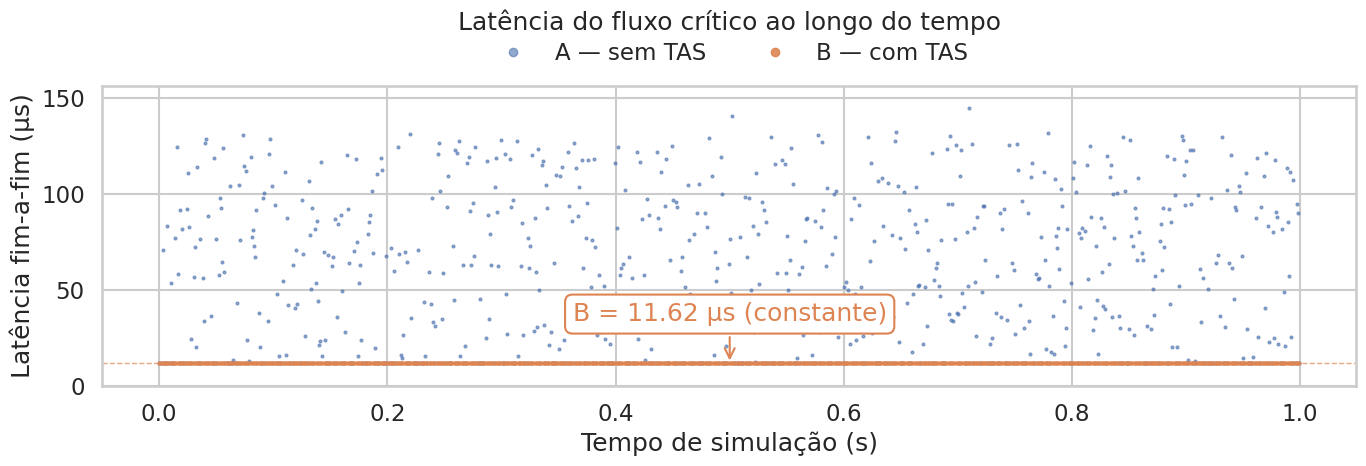

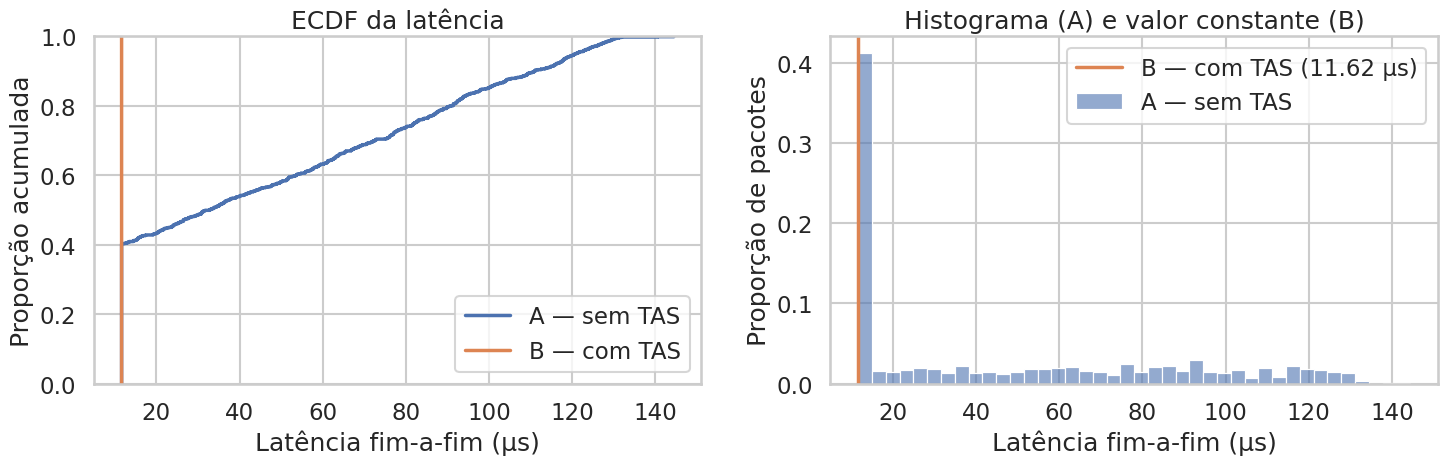

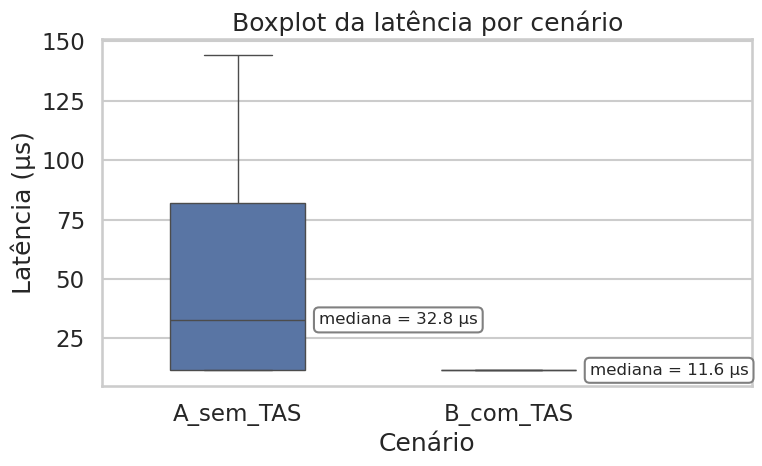

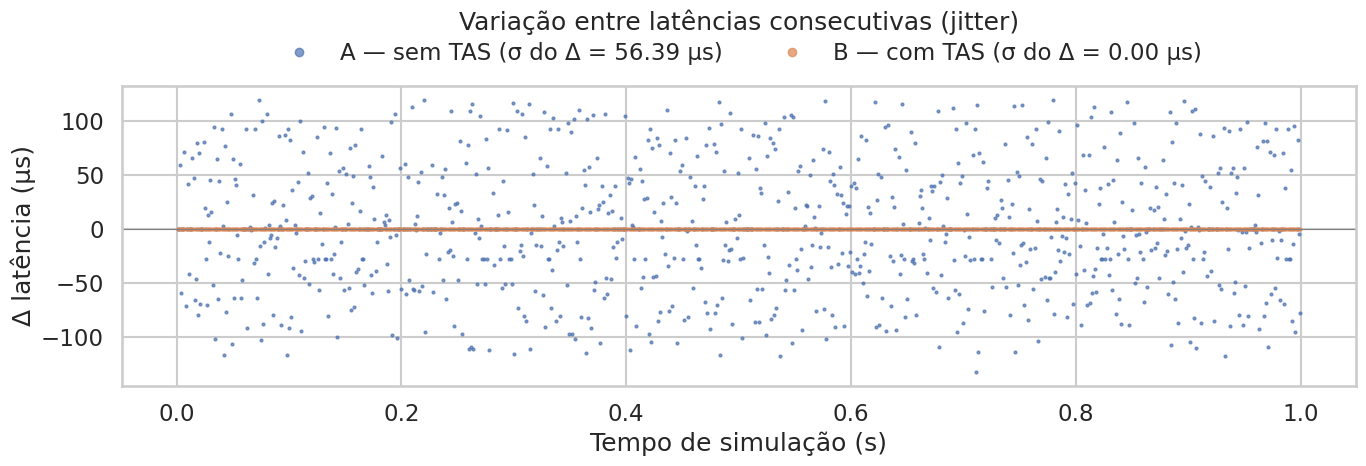

--- Cenário A (valores em µs) ---
                                                                                    count  \
module                                             name                                     
TimeAwareShapingShowcaseNetwork.server.app[1].sink meanBitLifeTimePerPacket:vector   1000   
                                                   packetLifeTime:vector             1000   

                                                                                      mean  \
module                                             name                                      
TimeAwareShapingShowcaseNetwork.server.app[1].sink meanBitLifeTimePerPacket:vector  47.846   
                                                   packetLifeTime:vector            47.846   

                                                                                       std  \
module                                             name                                      
TimeAwareShapingShowcaseNetw

In [41]:
# %% [markdown]
# ## 8. Gráficos comparativos
#
# Observação: o Cenário B é praticamente determinístico (latência constante),
# então os gráficos abaixo foram desenhados para que essa constante apareça
# como uma referência clara (linha/ponto) em vez de um pico que esmaga a escala.

# %% [markdown]
# ### 8.1 Série temporal da latência

# %%
A_us = df_A["latency"] * 1e6
B_us = df_B["latency"] * 1e6
B_ref = B_us.median()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_A["time"], A_us, ".", ms=4, alpha=0.6, label="A — sem TAS")
ax.plot(df_B["time"], B_us, ".", ms=4, alpha=0.9, color="C1", label="B — com TAS")
ax.axhline(B_ref, color="C1", lw=1, ls="--", alpha=0.7)
ax.annotate(f"B = {B_ref:.2f} µs (constante)", xy=(0.5, B_ref),
            xytext=(0.5, B_ref + 22), ha="center", color="C1",
            bbox=dict(boxstyle="round", fc="white", ec="C1"),
            arrowprops=dict(arrowstyle="->", color="C1"))
ax.set_ylim(0, A_us.max() * 1.08)
ax.set_xlabel("Tempo de simulação (s)")
ax.set_ylabel("Latência fim-a-fim (µs)")
ax.set_title("Latência do fluxo crítico ao longo do tempo", pad=40)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2,
          frameon=False, markerscale=3)
plt.tight_layout()
plt.show()

# %% [markdown]
# ### 8.2 Distribuição: ECDF e histograma
#
# Como B é uma constante, usamos a **ECDF** (que mostra bem tanto um degrau
# quanto uma distribuição espalhada) e, ao lado, um histograma de A com B
# marcado por uma linha vertical.

# %%
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

sns.ecdfplot(A_us, ax=ax1, label="A — sem TAS", lw=2.5)
sns.ecdfplot(B_us, ax=ax1, label="B — com TAS", lw=2.5)
ax1.set_xlabel("Latência fim-a-fim (µs)")
ax1.set_ylabel("Proporção acumulada")
ax1.set_title("ECDF da latência")
ax1.legend(loc="lower right")

sns.histplot(A_us, bins=40, stat="probability", color="C0", alpha=0.6,
             label="A — sem TAS", ax=ax2)
ax2.axvline(B_ref, color="C1", lw=2.5, label=f"B — com TAS ({B_ref:.2f} µs)")
ax2.set_xlabel("Latência fim-a-fim (µs)")
ax2.set_ylabel("Proporção de pacotes")
ax2.set_title("Histograma (A) e valor constante (B)")
ax2.legend()

plt.tight_layout()
plt.show()

# %% [markdown]
# ### 8.3 Boxplot comparativo

# %%
df_all = pd.concat([df_A, df_B], ignore_index=True)
df_all["latency_us"] = df_all["latency"] * 1e6
order = ["A_sem_TAS", "B_com_TAS"]

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df_all, x="scenario", y="latency_us", order=order, ax=ax,
            width=0.5, fliersize=2)
medians = df_all.groupby("scenario")["latency_us"].median()
for i, sc in enumerate(order):
    ax.text(i + 0.3, medians[sc], f"mediana = {medians[sc]:.1f} µs",
            ha="left", va="center", fontsize=12,
            bbox=dict(boxstyle="round", fc="white", ec="gray"))
ax.set_xlim(-0.5, 1.9)
ax.set_xlabel("Cenário")
ax.set_ylabel("Latência (µs)")
ax.set_title("Boxplot da latência por cenário")
plt.tight_layout()
plt.show()

# %% [markdown]
# ### 8.4 Jitter (diferença entre latências consecutivas)

# %%
fig, ax = plt.subplots(figsize=(14, 5))
for df, label, color in [(df_A, "A — sem TAS", "C0"), (df_B, "B — com TAS", "C1")]:
    diffs = df["latency"].diff().dropna() * 1e6
    ax.plot(df["time"].iloc[1:], diffs, ".", ms=4, alpha=0.7, color=color,
            label=f"{label} (σ do Δ = {diffs.std():.2f} µs)")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("Tempo de simulação (s)")
ax.set_ylabel("Δ latência (µs)")
ax.set_title("Variação entre latências consecutivas (jitter)", pad=40)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2,
          frameon=False, markerscale=3)
plt.tight_layout()
plt.show()

# %% [markdown]
# ### 8.5 Validação da métrica de latência
#
# `meanBitLifeTimePerPacket` é uma média por bit; `packetLifeTime` é o tempo
# de vida do pacote inteiro. Conferimos se ambas dão o mesmo resultado para o
# fluxo crítico (módulo `app[1]` do servidor), para garantir que a métrica
# escolhida representa de fato a latência fim-a-fim.

# %%
def lifetime_check(vec_df, label):
    sel = vec_df[vec_df["module"].str.contains("server.app[1]", regex=False)
                 & vec_df["name"].str.contains("LifeTime", case=False)]
    if sel.empty:
        print(f"{label}: nenhum vetor *LifeTime* em server.app[1]")
        return
    g = sel.groupby(["module", "name"])["value"].agg(["count", "mean", "std", "min", "max"])
    print(f"--- {label} (valores em µs) ---")
    print((g.assign(**{c: g[c] * 1e6 for c in ["mean", "std", "min", "max"]})).round(3))

lifetime_check(vec_A, "Cenário A")
lifetime_check(vec_B, "Cenário B")

In [42]:
# %% [markdown]
# ## 9. Tabela final comparativa

# %%
stats.round(3)

# %% [markdown]
# ## 10. Interpretação
#
# - **Cenário A (sem TAS):** a latência do fluxo crítico varia de ≈11,6 µs
#   (interface livre) até ≈144 µs. O limite superior é compatível com o
#   bloqueio por um quadro best-effort de 1500 B a 100 Mbps (~120 µs) somado
#   à transmissão do próprio pacote crítico. O jitter ≈ √2 × desvio padrão
#   indica latências sucessivas praticamente independentes, o que decorre da
#   chegada em fase aleatória do tráfego best-effort.
# - **Cenário B (com TAS):** a latência é constante (≈11,62 µs, valor que
#   corresponde ao tempo de transmissão sem fila), com desvio padrão e jitter
#   iguais a zero.
#
# **Ressalvas importantes**
#
# 1. O zero absoluto de jitter em B é resultado de um cenário **idealizado**:
#    a fonte crítica está sincronizada com a janela de gate (janela de 20 µs a
#    cada 1 ms). Sem sincronização (desvio de relógio, offset fonte–switch,
#    jitter na fonte), o pacote pode perder a janela e esperar o próximo ciclo.
# 2. Os resultados vêm de **uma única execução** de 1 s (1000 pacotes por
#    cenário). Para afirmações estatísticas, repetir com várias seeds
#    (`repeat`) e reportar intervalos de confiança.
# 3. A conclusão vale para o perfil de tráfego modelado (inspirado em OPC UA
#    PubSub); os resultados mostram que, **nesse cenário**, o TAS elimina a
#    interferência do tráfego best-effort sobre o fluxo crítico.


,Cenário A (sem TAS),Cenário B (com TAS)
n,1000.000,1000.00
mean_us,47.846,11.62
std_us,39.612,0.00
median_us,32.822,11.62
min_us,11.620,11.62
max_us,144.433,11.62
p95_us,120.671,11.62
p99_us,129.519,11.62
jitter_us,56.390,0.00


KeyError: (0, -1)

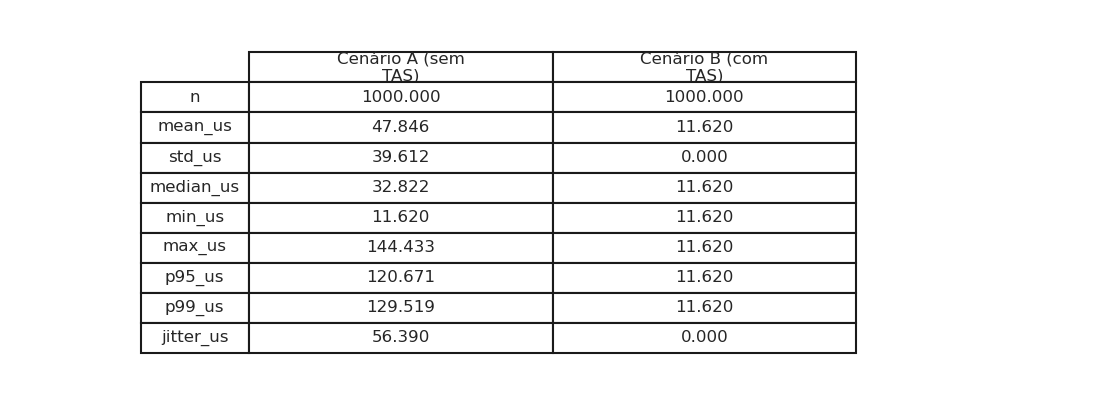

In [43]:
import textwrap

def render_table_nice(df, filename="tabela_final.png",
                      title="Estatísticas da latência do fluxo crítico (µs)",
                      figsize=(14, 5), fontsize=12):
    # Quebra nomes longos de colunas em duas linhas
    col_labels = [textwrap.fill(str(c), width=18) for c in df.columns]
    row_labels = [str(i) for i in df.index]

    # Formata valores
    cell_text = [[f"{v:.3f}" if isinstance(v, (int, float)) else str(v)
                  for v in row] for row in df.values]

    fig, ax = plt.subplots(figsize=figsize)
    ax.axis("off")

    table = ax.table(
        cellText=cell_text,
        rowLabels=row_labels,
        colLabels=col_labels,
        cellLoc="center",
        rowLoc="center",
        loc="center",
    )

    table.auto_set_font_size(False)
    table.set_fontsize(fontsize)
    table.scale(1.0, 1.8)  # largura base, altura das linhas

    # Ajustar largura das colunas conforme o conteúdo
    n_cols = len(df.columns)
    for col_idx in range(n_cols):
        max_len = max(
            len(str(df.columns[col_idx])),
            *[len(f"{v:.3f}") for v in df.iloc[:, col_idx]]
        )
        width = min(max(0.12, max_len * 0.018), 0.28)
        for row_idx in range(len(df) + 1):
            table[(row_idx, col_idx)].set_width(width)

    # Largura da coluna de rótulos
    max_row_len = max(len(r) for r in row_labels)
    label_width = min(max(0.15, max_row_len * 0.012), 0.30)
    for row_idx in range(len(df) + 1):
        table[(row_idx, -1)].set_width(label_width)

    # Estilo: cabeçalho em negrito com fundo claro
    for (row, col), cell in table.get_celld().items():
        cell.set_edgecolor("#bbbbbb")
        cell.set_linewidth(0.8)
        if row == 0:
            cell.set_facecolor("#e8f5e9")
            cell.set_text_props(weight="bold")
            cell.set_height(0.12)
        elif col == -1:
            cell.set_facecolor("#f5f5f5")
            cell.set_text_props(weight="bold")

    ax.set_title(title, fontsize=14, pad=16, weight="bold")
    plt.tight_layout()
    plt.savefig(filename, dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"Imagem salva em: {os.path.abspath(filename)}")


render_table_nice(stats.round(3), filename="tabela_final.png")